
# Titanic Survival Prediction
### Exploratory Data Analysis & Machine Learning

## 1. Introduction

The sinking of the RMS Titanic in 1912 is one of the most well-known maritime disasters in history.

In this project, we will explore passenger information to identify patterns associated with survival and develop machine learning models to predict whether a passenger survived.

Using features such as age, sex, passenger class, and fare, we will investigate survival patterns and build predictive models.

Our goal is to understand the data, develop meaningful insights, and apply machine learning techniques to solve a real-world classification problem.


## 2. Problem Definition

This project focuses on a binary classification problem.

The objective is to predict whether a Titanic passenger survived based on their available characteristics.

- Target variable: `Survived`
- Class 0: Did not survive
- Class 1: Survived

### Project Objectives

1. Explore and understand the dataset.
2. Identify patterns associated with passenger survival.
3. Perform data preprocessing.
4. Develop machine learning classification models.
5. Evaluate model performance.
6. Generate predictions for the competition test dataset.

In [1]:

# ==========================================
# 3. ENVIRONMENT SETUP
# ==========================================

# Import essential libraries

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

# Display settings

pd.set_option('display.max_columns', None)

# Set visualization style

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")


Libraries imported successfully!



## 4. Data Loading

In this section, we will load the three datasets provided by the Titanic competition.

- `train.csv`: Contains passenger information and survival labels.
- `test.csv`: Contains passenger information for prediction.
- `gender_submission.csv`: Provides a sample submission format.


In [2]:

# Load the competition datasets

train = pd.read_csv('/kaggle/input/competitions/titanic/train.csv')

test = pd.read_csv('/kaggle/input/competitions/titanic/test.csv')

submission = pd.read_csv('/kaggle/input/competitions/titanic/gender_submission.csv')

print("All datasets loaded successfully!")


All datasets loaded successfully!



## 5. Initial Data Inspection

Before performing exploratory data analysis, we will examine the structure and contents of the training dataset.

This initial inspection will help us understand:

- The number of observations and features.
- The meaning and data types of each feature.
- The presence of missing values.
- The distribution of the target variable.

Understanding these characteristics is essential before selecting appropriate data preprocessing techniques and machine learning algorithms.


In [3]:

# Display the first five rows of the training dataset

train.head()


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [4]:

# Check the dimensions of each dataset

print("Training dataset shape:", train.shape)
print("Testing dataset shape:", test.shape)
print("Submission dataset shape:", submission.shape)


Training dataset shape: (891, 12)
Testing dataset shape: (418, 11)
Submission dataset shape: (418, 2)


In [5]:
# Display column names and their data types

train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [6]:
# Count missing values in each column

missing_values = train.isnull().sum()

print("Missing values in each column:")
print(missing_values)

Missing values in each column:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


In [7]:
# Examine the survival distribution

print(train['Survived'].value_counts())

print("\nSurvival percentages:")
print(train['Survived'].value_counts(normalize=True) * 100)

Survived
0    549
1    342
Name: count, dtype: int64

Survival percentages:
Survived
0    61.616162
1    38.383838
Name: proportion, dtype: float64



## 6. Initial Data Analysis & Findings

Based on the initial inspection of the training dataset, the following observations were identified:

### Dataset Overview
- The training dataset contains 891 passenger records and 12 columns.
- The dataset includes numerical and categorical features.
- The target variable is `Survived`.

### Missing Values
- `Cabin` contains 687 missing values (approximately 77.10%).
- `Age` contains 177 missing values (approximately 19.87%).
- `Embarked` contains 2 missing values (approximately 0.22%).

### Survival Distribution
- 549 passengers (61.62%) did not survive.
- 342 passengers (38.38%) survived.

### Initial Observations

The dataset contains missing information, particularly in the `Cabin` and `Age` features. These missing values will require appropriate preprocessing.

The survival distribution also indicates that the target classes are not equally represented. We will consider this when selecting evaluation metrics for our machine learning models.

Further exploratory data analysis is required to investigate relationships between passenger characteristics and survival outcomes.



## 7. Exploratory Data Analysis (EDA)

Exploratory Data Analysis is the process of examining and visualizing datasets to discover patterns, relationships, trends, and potential anomalies.

In this section, we will investigate how different passenger characteristics relate to survival outcomes.

### 7.1 Survival Rate by Sex

We will examine the relationship between passenger sex and survival to determine whether survival rates differed between male and female passengers.


In [8]:
# Calculate survival rates by sex

survival_by_sex = train.groupby('Sex')['Survived'].mean() * 100

print("Survival rate by sex:")
print(survival_by_sex)

Survival rate by sex:
Sex
female    74.203822
male      18.890815
Name: Survived, dtype: float64


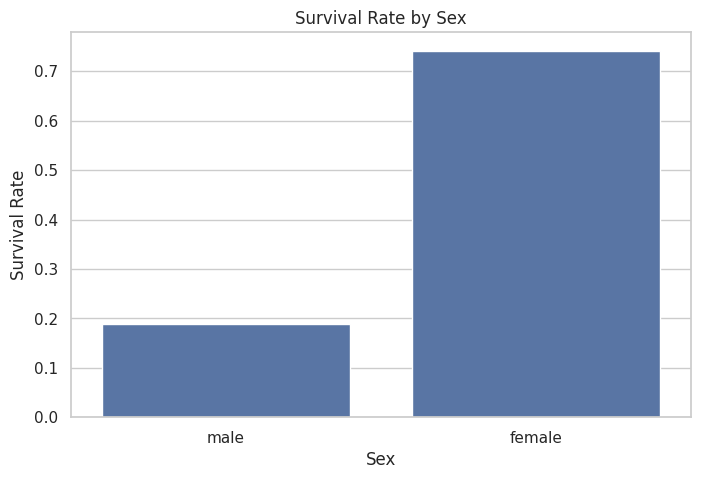

In [9]:
# Visualize survival rates by sex

plt.figure(figsize=(8, 5))

sns.barplot(
    data=train,
    x='Sex',
    y='Survived',
    errorbar=None
)

plt.title('Survival Rate by Sex')
plt.xlabel('Sex')
plt.ylabel('Survival Rate')
plt.show()


### 7.1 Findings: Survival Rate by Sex

The analysis reveals a substantial difference in survival rates between female and male passengers.

- Female passengers had a survival rate of approximately 74.20%.
- Male passengers had a survival rate of approximately 18.89%.

The results indicate that female passengers in the training dataset were considerably more likely to survive than male passengers.

This suggests that passenger sex may be an important predictive feature for our machine learning models.

**Conclusion:** Sex demonstrates a strong association with survival and should be considered during model development.



### 7.2 Survival Rate by Passenger Class

In this investigation, we will examine whether passenger class was associated with survival outcomes.

The Titanic dataset categorizes passengers into three classes: first class, second class, and third class.

We will calculate and visualize the survival rate for each passenger class to identify potential differences.

In [10]:
# Calculate survival rates by passenger class

survival_by_class = train.groupby('Pclass')['Survived'].mean() * 100

print("Survival rate by passenger class:")
print(survival_by_class)

Survival rate by passenger class:
Pclass
1    62.962963
2    47.282609
3    24.236253
Name: Survived, dtype: float64


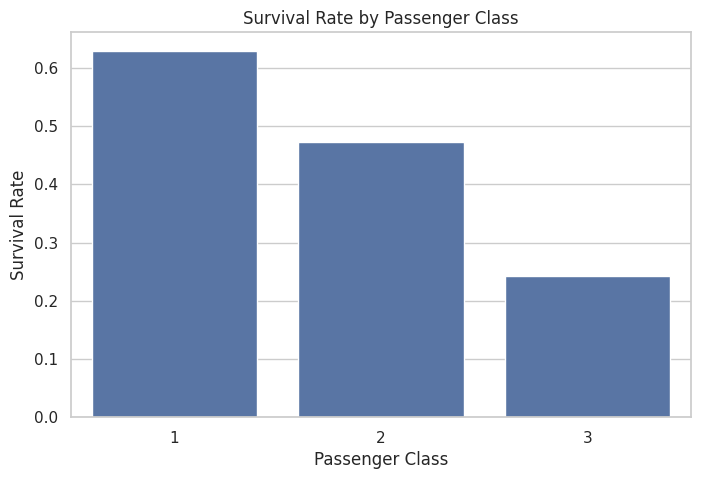

In [11]:
# Visualize survival rates by passenger class

plt.figure(figsize=(8, 5))

sns.barplot(
    data=train,
    x='Pclass',
    y='Survived',
    errorbar=None
)

plt.title('Survival Rate by Passenger Class')
plt.xlabel('Passenger Class')
plt.ylabel('Survival Rate')
plt.show()

### 7.2 Findings: Survival Rate by Passenger Class

The analysis reveals a clear relationship between passenger class and survival rates.

- First-class passengers had a survival rate of approximately 62.96%.
- Second-class passengers had a survival rate of approximately 47.28%.
- Third-class passengers had a survival rate of approximately 24.24%.

Passengers travelling in first class had the highest survival rate, while third-class passengers had the lowest.

This suggests that passenger class may be an important predictive feature for our machine learning models.

**Conclusion:** Passenger class demonstrates a noticeable association with survival.

### 7.3 Survival Rate by Age

In this section, we will examine how passenger age relates to survival. We will group passengers into age categories to compare their survival rates.

In [12]:
# Create age groups

train['AgeGroup'] = pd.cut(
    train['Age'],
    bins=[0, 12, 18, 35, 60, 100],
    labels=['Child', 'Teenager', 'Young Adult', 'Adult', 'Senior']
)

# Calculate survival rates by age group

survival_by_age = train.groupby(
    'AgeGroup',
    observed=False
)['Survived'].mean() * 100

print("Survival rate by age group:")
print(survival_by_age)

Survival rate by age group:
AgeGroup
Child          57.971014
Teenager       42.857143
Young Adult    38.268156
Adult          40.000000
Senior         22.727273
Name: Survived, dtype: float64


### 7.3 Findings: Survival Rate by Age

The analysis reveals differences in survival rates across passenger age groups.

- Children had the highest survival rate of approximately 57.97%.
- Teenagers had a survival rate of approximately 42.86%.
- Young adults had a survival rate of approximately 38.27%.
- Adults had a survival rate of approximately 40.00%.
- Seniors had the lowest survival rate of approximately 22.73%.

The results suggest that age may be an important feature associated with passenger survival.

**Conclusion:** Age may provide useful information for predicting survival. However, the number of passengers in each age group should also be considered when interpreting these results.

### 7.4 Survival Rate by Fare

In [13]:
# Create fare groups

train['FareGroup'] = pd.qcut(
    train['Fare'],
    q=4,
    labels=['Low', 'Medium', 'High', 'Very High']
)

# Calculate survival rates by fare group

survival_by_fare = train.groupby(
    'FareGroup',
    observed=False
)['Survived'].mean() * 100

print("Survival rate by fare group:")
print(survival_by_fare)

Survival rate by fare group:
FareGroup
Low          19.730942
Medium       30.357143
High         45.495495
Very High    58.108108
Name: Survived, dtype: float64


### 7.4 Findings: Survival Rate by Fare

The analysis reveals a positive relationship between fare groups and survival rates.

- Passengers in the low-fare group had a survival rate of approximately 19.73%.
- The medium-fare group had a survival rate of approximately 30.36%.
- The high-fare group had a survival rate of approximately 45.50%.
- The very-high-fare group had the highest survival rate of approximately 58.11%.

Survival rates generally increased as passenger fare increased.

This relationship may partly reflect the association between fare and passenger class.

**Conclusion:** Fare may be a useful predictive feature for our machine learning models.

### 7.5 Survival Rate by Family Size

In this section, we will investigate whether the number of family members travelling with a passenger was associated with their survival.

In [14]:
# Calculate family size

train['FamilySize'] = train['SibSp'] + train['Parch'] + 1

# Calculate survival rates by family size

survival_by_family = train.groupby(
    'FamilySize'
)['Survived'].mean() * 100

print("Survival rate by family size:")
print(survival_by_family)

Survival rate by family size:
FamilySize
1     30.353818
2     55.279503
3     57.843137
4     72.413793
5     20.000000
6     13.636364
7     33.333333
8      0.000000
11     0.000000
Name: Survived, dtype: float64


### 7.5 Findings: Survival Rate by Family Size

The analysis reveals differences in survival rates based on the number of family members travelling together.

- Passengers travelling alone had a survival rate of approximately 30.35%.
- Passengers with family sizes of 2, 3, and 4 had higher survival rates.
- Family size 4 recorded the highest survival rate of approximately 72.41%.
- Larger family groups, particularly those with 5 and 6 members, had lower survival rates.

The results suggest that travelling with a small family may have been associated with better survival outcomes.

However, survival rates for larger family groups should be interpreted cautiously because some groups may contain relatively few passengers.

**Conclusion:** Family size may be a useful feature for predicting passenger survival.

In [15]:
# Calculate survival rates by embarkation port

survival_by_embarked = train.groupby(
    'Embarked'
)['Survived'].mean() * 100

print("Survival rate by embarkation port:")
print(survival_by_embarked)

Survival rate by embarkation port:
Embarked
C    55.357143
Q    38.961039
S    33.695652
Name: Survived, dtype: float64


### 7.6 Findings: Survival Rate by Embarkation Port

The analysis reveals differences in survival rates among passengers who boarded the Titanic at different ports.

- Cherbourg (C) had the highest survival rate of approximately 55.36%.
- Queenstown (Q) had a survival rate of approximately 38.96%.
- Southampton (S) had the lowest survival rate of approximately 33.70%.

These results suggest that the embarkation port may provide useful information for predicting passenger survival.

However, the differences may also be related to other passenger characteristics, such as passenger class and fare.

**Conclusion:** Embarkation port may be a useful predictive feature for our machine learning models.

### 7.7 Missing Values Analysis

In [16]:
# Calculate missing values

missing_values = train.isnull().sum()

# Calculate missing value percentages

missing_percentage = (missing_values / len(train)) * 100

# Combine the results into a DataFrame

missing_summary = pd.DataFrame({
    'Missing Values': missing_values,
    'Missing Percentage': missing_percentage
})

# Display columns with missing values

missing_summary = missing_summary[
    missing_summary['Missing Values'] > 0
].sort_values(by='Missing Percentage', ascending=False)

print("Missing Values Summary:")
display(missing_summary)

Missing Values Summary:


,Missing Values,Missing Percentage
Cabin,687,77.104377
Age,177,19.865320
AgeGroup,177,19.865320
Embarked,2,0.224467


### 7.7 Findings: Missing Values Analysis

The missing-values analysis identifies three original features containing missing data.

- Cabin has 687 missing values, representing approximately 77.10% of the training dataset.
- Age has 177 missing values, representing approximately 19.87%.
- Embarked has only 2 missing values, representing approximately 0.22%.

The AgeGroup feature also contains 177 missing values because it was derived from Age.

These findings will guide our data preprocessing decisions.

**Conclusion:** Missing values must be handled carefully before model development. Age and Embarked can be imputed, while Cabin requires further consideration because of its high percentage of missing values.

## 8. EDA Summary and Key Findings

The exploratory data analysis revealed several relationships between passenger characteristics and survival.

### Key Observations

1. **Sex:** Female passengers had a considerably higher survival rate than male passengers.
2. **Passenger Class:** First-class passengers had higher survival rates than second- and third-class passengers.
3. **Age:** Children had the highest survival rate among the age groups examined.
4. **Fare:** Passengers who paid higher fares generally had higher survival rates.
5. **Family Size:** Passengers travelling with smaller families generally had better survival outcomes than those travelling alone or in larger families.
6. **Embarkation Port:** Passengers who embarked at Cherbourg had the highest survival rate.
7. **Missing Values:** Age, Cabin, and Embarked contain missing values that require appropriate preprocessing.

### Overall Conclusion

The analysis suggests that passenger characteristics such as sex, passenger class, age, fare, and family size may provide useful information for predicting survival.

These findings will guide feature selection and data preprocessing before developing machine learning models.

## 9. Data Preprocessing

In this section, we will prepare the Titanic dataset for machine learning.

The preprocessing steps include handling missing values, creating useful features, encoding categorical variables, and preparing the final datasets for model training and prediction.

### 9.1 Preparing the Datasets

We will separate the target variable (`Survived`) from the passenger features.

The training dataset contains the survival labels, while the test dataset will be used later to generate predictions.

In [17]:
# Create a copy of the original datasets

train_processed = train.copy()
test_processed = test.copy()

# Separate target variable from training features

X = train_processed.drop('Survived', axis=1)
y = train_processed['Survived']

# Display dataset dimensions

print("Training features shape:", X.shape)
print("Target variable shape:", y.shape)
print("Test dataset shape:", test_processed.shape)

Training features shape: (891, 14)
Target variable shape: (891,)
Test dataset shape: (418, 11)


### 9.2 Identifying Missing Values

Before training our machine learning model, we need to identify missing values in both the training and test datasets.

This will help us determine appropriate imputation strategies for each feature.

In [18]:
# Check missing values in training features

print("Missing values in training features:")
display(X.isnull().sum()[X.isnull().sum() > 0])

# Check missing values in test dataset

print("\nMissing values in test dataset:")
display(test_processed.isnull().sum()[test_processed.isnull().sum() > 0])

Missing values in training features:


Age         177
Cabin       687
Embarked      2
AgeGroup    177
dtype: int64


Missing values in test dataset:


Age       86
Fare       1
Cabin    327
dtype: int64

### 9.3 Removing Temporary EDA Features

During exploratory data analysis, we created AgeGroup and FareGroup to investigate survival patterns.

These columns were created for analysis and are not yet prepared for model training.

We will remove them and recreate any useful engineered features consistently in both training and test datasets.

In [19]:
# Remove temporary EDA columns

columns_to_drop = ['AgeGroup', 'FareGroup']

X = X.drop(columns=columns_to_drop, errors='ignore')

# Check the updated training features

print("Updated training features shape:", X.shape)
print("Test dataset shape:", test_processed.shape)

print("\nTraining columns:")
print(X.columns.tolist())

print("\nTest columns:")
print(test_processed.columns.tolist())

Updated training features shape: (891, 12)
Test dataset shape: (418, 11)

Training columns:
['PassengerId', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked', 'FamilySize']

Test columns:
['PassengerId', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']


### 9.4 Feature Engineering: Family Size

We will create a FamilySize feature for both training and test datasets.

FamilySize represents the total number of family members travelling with a passenger, including the passenger themselves.

Formula:

FamilySize = SibSp + Parch + 1

In [20]:
# Create FamilySize in both datasets

X['FamilySize'] = X['SibSp'] + X['Parch'] + 1

test_processed['FamilySize'] = (
    test_processed['SibSp'] + test_processed['Parch'] + 1
)

# Compare dataset columns

print("Training features shape:", X.shape)
print("Test dataset shape:", test_processed.shape)

print("\nDo both datasets have matching columns?")
print(X.columns.tolist() == test_processed.columns.tolist())

Training features shape: (891, 12)
Test dataset shape: (418, 12)

Do both datasets have matching columns?
True


### 9.5 Feature Engineering: Cabin Deck

The Cabin feature contains a large number of missing values.

To preserve potentially useful information, we will extract the first letter of each cabin number as a new feature called Deck.

Missing cabin information will be represented as "Unknown".

After extracting the deck information, we will remove the original Cabin column.

In [21]:
# Extract deck information from Cabin

X['Deck'] = X['Cabin'].str[0].fillna('Unknown')

test_processed['Deck'] = (
    test_processed['Cabin'].str[0].fillna('Unknown')
)

# Remove the original Cabin column

X = X.drop('Cabin', axis=1)
test_processed = test_processed.drop('Cabin', axis=1)

# Inspect the new feature

print("Deck distribution in training data:")
print(X['Deck'].value_counts())

print("\nUpdated training shape:", X.shape)
print("Updated test shape:", test_processed.shape)

print("\nDo both datasets have matching columns?")
print(X.columns.tolist() == test_processed.columns.tolist())

Deck distribution in training data:
Deck
Unknown    687
C           59
B           47
D           33
E           32
A           15
F           13
G            4
T            1
Name: count, dtype: int64

Updated training shape: (891, 12)
Updated test shape: (418, 12)

Do both datasets have matching columns?
True


### 9.6 Handling Missing Values

Missing values can prevent machine learning algorithms from processing the dataset correctly.

We will use the following imputation strategies:

- Age: Replace missing values with the median age.
- Embarked: Replace missing values with the most frequent embarkation port (mode).
- Fare: Replace missing values with the median fare.

The imputation values will be calculated from the training dataset and consistently applied to the test dataset.

In [22]:
# Calculate imputation values using training data only

age_median = X['Age'].median()
fare_median = X['Fare'].median()
embarked_mode = X['Embarked'].mode()[0]

# Apply the same imputation values to both datasets

for dataset in [X, test_processed]:

    dataset['Age'] = dataset['Age'].fillna(age_median)

    dataset['Fare'] = dataset['Fare'].fillna(fare_median)

    dataset['Embarked'] = dataset['Embarked'].fillna(embarked_mode)

# Display the imputation values

print("Imputation values:")
print("Age median:", age_median)
print("Fare median:", fare_median)
print("Embarked mode:", embarked_mode)

# Check remaining missing values

print("\nMissing values in training features:")
print(X.isnull().sum()[X.isnull().sum() > 0])

print("\nMissing values in test dataset:")
print(test_processed.isnull().sum()[test_processed.isnull().sum() > 0])

Imputation values:
Age median: 28.0
Fare median: 14.4542
Embarked mode: S

Missing values in training features:
Series([], dtype: int64)

Missing values in test dataset:
Series([], dtype: int64)


### 9.7 Feature Engineering: Extracting Passenger Titles

Passenger names contain titles that may provide useful information for survival prediction.

We will extract titles such as Mr, Mrs, Miss, Master, and Dr from passenger names.

This will allow us to create a new categorical feature called Title instead of relying on the complete passenger name.

In [23]:
# Extract passenger titles from names

for dataset in [X, test_processed]:

    dataset['Title'] = dataset['Name'].str.extract(
        r',\s*([^.]*)\.',
        expand=False
    )

# Display title distributions

print("Passenger titles in training data:")
display(X['Title'].value_counts())

print("\nPassenger titles in test data:")
display(test_processed['Title'].value_counts())

Passenger titles in training data:


Title
Mr              517
Miss            182
Mrs             125
Master           40
Dr                7
Rev               6
Col               2
Mlle              2
Major             2
Ms                1
Mme               1
Don               1
Lady              1
Sir               1
Capt              1
the Countess      1
Jonkheer          1
Name: count, dtype: int64


Passenger titles in test data:


Title
Mr        240
Miss       78
Mrs        72
Master     21
Col         2
Rev         2
Ms          1
Dr          1
Dona        1
Name: count, dtype: int64

#### Findings: Passenger Titles

The title distribution reveals four dominant categories: Mr, Mrs, Miss, and Master.

Several other titles occur infrequently in the datasets. To reduce the number of categorical values, uncommon titles will be grouped into a single category called Rare.

Some alternative title spellings will also be standardized:

- Mlle and Ms will be mapped to Miss.
- Mme will be mapped to Mrs.

The original Name column will be removed after extracting the Title feature.

**Conclusion:** Passenger titles provide potentially useful information for survival prediction while reducing the complexity of the original Name feature.

In [24]:
# Standardize alternative title names

title_mapping = {
    'Mlle': 'Miss',
    'Ms': 'Miss',
    'Mme': 'Mrs'
}

# Apply consistent title transformations

for dataset in [X, test_processed]:

    # Standardize alternative titles
    dataset['Title'] = dataset['Title'].replace(title_mapping)

    # Preserve common titles and group the remaining titles
    dataset['Title'] = dataset['Title'].where(
        dataset['Title'].isin(['Mr', 'Mrs', 'Miss', 'Master']),
        'Rare'
    )

    # Remove the original Name column
    dataset.drop('Name', axis=1, inplace=True)


# Display the updated title distributions

print("Training title distribution:")
display(X['Title'].value_counts())

print("\nTest title distribution:")
display(test_processed['Title'].value_counts())

# Verify matching columns

print("\nDo both datasets have matching columns?")
print(X.columns.tolist() == test_processed.columns.tolist())

Training title distribution:


Title
Mr        517
Miss      185
Mrs       126
Master     40
Rare       23
Name: count, dtype: int64


Test title distribution:


Title
Mr        240
Miss       79
Mrs        72
Master     21
Rare        6
Name: count, dtype: int64


Do both datasets have matching columns?
True


### 9.9 Identifying Categorical Features

Machine learning algorithms generally require numerical input.

Before encoding categorical features, we will inspect the data types and unique values in both datasets.

This will help us identify suitable encoding strategies and determine whether any identifier or high-cardinality columns should be removed.

In [25]:
# Inspect data types in the training dataset

print("Training dataset data types:")
display(X.dtypes)

# Identify categorical columns

categorical_columns = X.select_dtypes(
    include=['object']
).columns

# Count unique values in categorical columns

print("\nUnique values in categorical features:")

for column in categorical_columns:

    print(
        f"{column}: "
        f"{X[column].nunique()} unique values"
    )

# Inspect the number of unique passenger identifiers

print("\nUnique PassengerId values:", X['PassengerId'].nunique())

Training dataset data types:


PassengerId      int64
Pclass           int64
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Embarked        object
FamilySize       int64
Deck            object
Title           object
dtype: object


Unique values in categorical features:
Sex: 2 unique values
Ticket: 681 unique values
Embarked: 3 unique values
Deck: 9 unique values
Title: 5 unique values

Unique PassengerId values: 891


### 9.10 Removing Identifier and High-Cardinality Features

PassengerId is a unique identifier rather than a meaningful passenger characteristic, so it will be excluded from model training.

We will preserve the PassengerId values from the test dataset for the final Kaggle submission.

The Ticket feature contains many unique values. To avoid unnecessarily increasing the dimensionality of our initial model, we will remove the original Ticket feature.

These decisions simplify the dataset while retaining potentially useful passenger characteristics.

In [26]:
# Preserve test passenger IDs from the original dataset

test_passenger_ids = test['PassengerId'].copy()

# Remove unnecessary columns from both datasets
# errors='ignore' prevents errors if a column was already removed

columns_to_drop = ['PassengerId', 'Ticket']

X = X.drop(columns=columns_to_drop, errors='ignore')

test_processed = test_processed.drop(
    columns=columns_to_drop,
    errors='ignore'
)

# Display updated dataset dimensions

print("Training features shape:", X.shape)
print("Test dataset shape:", test_processed.shape)

# Verify matching columns

print("\nDo both datasets have matching columns?")
print(X.columns.tolist() == test_processed.columns.tolist())

print("\nRemaining features:")
print(X.columns.tolist())

# Verify preserved passenger IDs

print("\nNumber of preserved test passenger IDs:")
print(len(test_passenger_ids))

Training features shape: (891, 10)
Test dataset shape: (418, 10)

Do both datasets have matching columns?
True

Remaining features:
['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked', 'FamilySize', 'Deck', 'Title']

Number of preserved test passenger IDs:
418


### 9.11 Categorical Feature Encoding

Machine learning algorithms generally require numerical input features.

We will use One-Hot Encoding to transform categorical features into numerical representations.

The categorical features selected for encoding are:

- Sex
- Embarked
- Deck
- Title

We will use drop_first=True to remove one reference category from each feature and reduce redundant columns.

The training and test datasets will be aligned to ensure that they contain exactly the same encoded features.

In [27]:
# Identify categorical features

categorical_columns = [
    'Sex',
    'Embarked',
    'Deck',
    'Title'
]

# Apply One-Hot Encoding to training data

X_encoded = pd.get_dummies(
    X,
    columns=categorical_columns,
    drop_first=True,
    dtype=int
)

# Apply One-Hot Encoding to test data

test_encoded = pd.get_dummies(
    test_processed,
    columns=categorical_columns,
    drop_first=True,
    dtype=int
)

# Align test features with training features

test_encoded = test_encoded.reindex(
    columns=X_encoded.columns,
    fill_value=0
)

# Update datasets

X = X_encoded.copy()
test_processed = test_encoded.copy()

# Display results

print("Encoded training dataset shape:", X.shape)
print("Encoded test dataset shape:", test_processed.shape)

print("\nDo both datasets have matching columns?")
print(X.columns.tolist() == test_processed.columns.tolist())

print("\nEncoded feature names:")
print(X.columns.tolist())

print("\nTraining dataset data types:")
print(X.dtypes)

Encoded training dataset shape: (891, 21)
Encoded test dataset shape: (418, 21)

Do both datasets have matching columns?
True

Encoded feature names:
['Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'FamilySize', 'Sex_male', 'Embarked_Q', 'Embarked_S', 'Deck_B', 'Deck_C', 'Deck_D', 'Deck_E', 'Deck_F', 'Deck_G', 'Deck_T', 'Deck_Unknown', 'Title_Miss', 'Title_Mr', 'Title_Mrs', 'Title_Rare']

Training dataset data types:
Pclass            int64
Age             float64
SibSp             int64
Parch             int64
Fare            float64
FamilySize        int64
Sex_male          int64
Embarked_Q        int64
Embarked_S        int64
Deck_B            int64
Deck_C            int64
Deck_D            int64
Deck_E            int64
Deck_F            int64
Deck_G            int64
Deck_T            int64
Deck_Unknown      int64
Title_Miss        int64
Title_Mr          int64
Title_Mrs         int64
Title_Rare        int64
dtype: object


### 9.12 Final Preprocessing Validation

In this section, we will verify that the training and test datasets are ready for machine learning.

We will check:

- Missing values
- Non-numerical features
- Matching feature columns
- Dataset dimensions
- Target variable dimensions

In [28]:
# Check missing values

print("Missing values in training features:", X.isnull().sum().sum())
print("Missing values in test features:", test_processed.isnull().sum().sum())

# Check for non-numerical columns

print("\nNon-numerical training columns:")
print(X.select_dtypes(exclude=np.number).columns.tolist())

print("\nNon-numerical test columns:")
print(test_processed.select_dtypes(exclude=np.number).columns.tolist())

# Check feature alignment

print("\nDo training and test columns match?")
print(X.columns.equals(test_processed.columns))

# Check dataset dimensions

print("\nTraining features:", X.shape)
print("Target variable:", y.shape)
print("Test features:", test_processed.shape)
print("Preserved passenger IDs:", len(test_passenger_ids))

# Check target distribution

print("\nTarget variable distribution:")
print(y.value_counts())

Missing values in training features: 0
Missing values in test features: 0

Non-numerical training columns:
[]

Non-numerical test columns:
[]

Do training and test columns match?
True

Training features: (891, 21)
Target variable: (891,)
Test features: (418, 21)
Preserved passenger IDs: 418

Target variable distribution:
Survived
0    549
1    342
Name: count, dtype: int64


## 10. Model Development

In this section, we will develop machine learning models to predict whether Titanic passengers survived.

We will begin by dividing the labelled training dataset into training and validation sets.

The training set will be used to develop the model, while the validation set will be used to evaluate its predictive performance.

### 10.1 Training and Validation Split

We will use an 80:20 split.

- 80% of the labelled data will be used for model training.
- 20% will be reserved for model validation.

We will use stratified sampling to maintain approximately the same survival-class proportions in both sets.

In [29]:
from sklearn.model_selection import train_test_split

# Rebuild features from the original training dataset

def create_model_features(df):

    data = df.copy()

    # Create FamilySize
    data['FamilySize'] = (
        data['SibSp'] + data['Parch'] + 1
    )

    # Extract cabin deck
    data['Deck'] = data['Cabin'].str[0].fillna('Unknown')

    # Extract passenger title
    data['Title'] = data['Name'].str.extract(
        r',\s*([^.]*)\.',
        expand=False
    )

    # Standardize alternative titles
    data['Title'] = data['Title'].replace({
        'Mlle': 'Miss',
        'Ms': 'Miss',
        'Mme': 'Mrs'
    })

    # Group uncommon titles
    data['Title'] = data['Title'].where(
        data['Title'].isin(['Mr', 'Mrs', 'Miss', 'Master']),
        'Rare'
    )

    # Remove unnecessary original columns
    data = data.drop(
        columns=['PassengerId', 'Name', 'Ticket', 'Cabin']
    )

    return data


# Prepare features and target

X_model = create_model_features(
    train.drop(
        columns=['Survived', 'AgeGroup', 'FareGroup', 'FamilySize'],
        errors='ignore'
    )
)

y_model = train['Survived'].copy()


# Split the dataset

X_train, X_valid, y_train, y_valid = train_test_split(
    X_model,
    y_model,
    test_size=0.20,
    random_state=42,
    stratify=y_model
)


# Display split information

print("Training features shape:", X_train.shape)
print("Validation features shape:", X_valid.shape)

print("Training target shape:", y_train.shape)
print("Validation target shape:", y_valid.shape)

print("\nTraining survival distribution (%):")
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nValidation survival distribution (%):")
print((y_valid.value_counts(normalize=True) * 100).round(2))

Training features shape: (712, 10)
Validation features shape: (179, 10)
Training target shape: (712,)
Validation target shape: (179,)

Training survival distribution (%):
Survived
0    61.66
1    38.34
Name: proportion, dtype: float64

Validation survival distribution (%):
Survived
0    61.45
1    38.55
Name: proportion, dtype: float64


### 10.2 Logistic Regression

Logistic Regression is a supervised machine learning algorithm commonly used for binary classification.

In this project, it will predict whether a passenger survived the Titanic disaster.

We will use a Scikit-learn preprocessing pipeline to:

- Replace missing numerical values with their median.
- Replace missing categorical values with their most frequent value.
- Standardize numerical features.
- One-hot encode categorical features.

The preprocessing transformations will be fitted using only the training subset to prevent data leakage.

In [30]:
# Import required libraries

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression

# Identify numerical and categorical features

numeric_features = [
    'Pclass',
    'Age',
    'SibSp',
    'Parch',
    'Fare',
    'FamilySize'
]

categorical_features = [
    'Sex',
    'Embarked',
    'Deck',
    'Title'
]

# Create numerical preprocessing pipeline

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Create categorical preprocessing pipeline

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(
        handle_unknown='ignore',
        drop='first'
    ))
])

# Combine preprocessing transformations

preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

# Create Logistic Regression pipeline

logistic_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000))
])

# Train the model

logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


### 10.3 Model Evaluation

We will evaluate the Logistic Regression model using the validation dataset.

The evaluation metrics will include:

- Accuracy
- Precision
- Recall
- F1-score
- Confusion Matrix

These metrics will help us understand how well the model predicts passenger survival.

In [31]:
# Import evaluation metrics

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Generate validation predictions

y_pred = logistic_model.predict(X_valid)

# Calculate accuracy

accuracy = accuracy_score(y_valid, y_pred)

print("Logistic Regression Model Evaluation")
print("-------------------------------------")

print(f"Accuracy: {accuracy * 100:.2f}%")

# Display classification report

print("\nClassification Report:")
print(classification_report(
    y_valid,
    y_pred,
    target_names=['Did Not Survive', 'Survived']
))

# Display confusion matrix

print("Confusion Matrix:")
print(confusion_matrix(y_valid, y_pred))

Logistic Regression Model Evaluation
-------------------------------------
Accuracy: 82.12%

Classification Report:
                 precision    recall  f1-score   support

Did Not Survive       0.83      0.89      0.86       110
       Survived       0.80      0.71      0.75        69

       accuracy                           0.82       179
      macro avg       0.82      0.80      0.81       179
   weighted avg       0.82      0.82      0.82       179

Confusion Matrix:
[[98 12]
 [20 49]]


### 10.3 Findings: Logistic Regression Evaluation

The Logistic Regression model achieved an accuracy of approximately 82.12% on the validation dataset.

The classification report produced the following results for the survival class:

- Precision: 0.80
- Recall: 0.71
- F1-score: 0.75

The confusion matrix showed that the model correctly classified 98 passengers who did not survive and 49 passengers who survived.

However, it incorrectly classified 12 non-survivors as survivors and failed to identify 20 actual survivors.

The model demonstrated better performance in identifying passengers who did not survive than passengers who survived.

**Conclusion:** Logistic Regression provides a promising baseline model with 82.12% validation accuracy. Further model comparisons may help improve predictive performance.

### 10.4 Random Forest Classifier

Random Forest is an ensemble machine learning algorithm that combines predictions from multiple decision trees.

Each decision tree learns patterns from the training data, and the forest combines their predictions to produce a final classification.

We will train a Random Forest model using the same training and validation split used for Logistic Regression.

This will allow us to compare the performance of two different machine learning algorithms.

In [32]:
# Import required libraries

from sklearn.ensemble import RandomForestClassifier
from sklearn.base import clone

# Create Random Forest pipeline

random_forest_model = Pipeline(steps=[
    ('preprocessor', clone(preprocessor)),
    ('classifier', RandomForestClassifier(
        n_estimators=300,
        random_state=42
    ))
])

# Train the model

random_forest_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


### 10.5 Random Forest Model Evaluation

We will evaluate the Random Forest model using the same validation dataset used for Logistic Regression.

The evaluation will include accuracy, precision, recall, F1-score, and a confusion matrix.

This will help us compare the predictive performance of both algorithms.

In [33]:
# Generate validation predictions

y_pred_rf = random_forest_model.predict(X_valid)

# Calculate accuracy

rf_accuracy = accuracy_score(y_valid, y_pred_rf)

print("Random Forest Model Evaluation")
print("--------------------------------")

print(f"Accuracy: {rf_accuracy * 100:.2f}%")

# Display classification report

print("\nClassification Report:")

print(classification_report(
    y_valid,
    y_pred_rf,
    target_names=['Did Not Survive', 'Survived']
))

# Display confusion matrix

print("Confusion Matrix:")

print(confusion_matrix(y_valid, y_pred_rf))

Random Forest Model Evaluation
--------------------------------
Accuracy: 79.89%

Classification Report:
                 precision    recall  f1-score   support

Did Not Survive       0.82      0.86      0.84       110
       Survived       0.76      0.70      0.73        69

       accuracy                           0.80       179
      macro avg       0.79      0.78      0.78       179
   weighted avg       0.80      0.80      0.80       179

Confusion Matrix:
[[95 15]
 [21 48]]


### 10.5 Findings: Random Forest Model Evaluation

The Random Forest model achieved an accuracy of approximately 79.89% on the validation dataset.

The classification report produced the following results for the survival class:

- Precision: 0.76
- Recall: 0.70
- F1-score: 0.73

The confusion matrix showed that the model correctly classified 95 passengers who did not survive and 48 passengers who survived.

It incorrectly classified 15 non-survivors as survivors and failed to identify 21 actual survivors.

**Conclusion:** Random Forest achieved reasonable predictive performance. However, Logistic Regression performed slightly better across the evaluated metrics on this validation split.

### 10.6 Model Comparison Using Cross-Validation

To obtain a more reliable estimate of model performance, we will use 5-fold stratified cross-validation.

The dataset will be divided into five folds while maintaining the approximate survival-class distribution.

Both Logistic Regression and Random Forest will be evaluated using:

- Accuracy
- F1-score

The preprocessing pipelines will be fitted independently within each fold to avoid data leakage.

We will compare the average performance and variability of both algorithms.

In [34]:
# Import cross-validation tools

from sklearn.model_selection import StratifiedKFold, cross_validate

# Create stratified 5-fold cross-validation

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Define models for comparison

models = {
    'Logistic Regression': logistic_model,
    'Random Forest': random_forest_model
}

# Store cross-validation results

cv_summary = {}

for model_name, model in models.items():

    scores = cross_validate(
        model,
        X_model,
        y_model,
        cv=cv,
        scoring={
            'accuracy': 'accuracy',
            'f1': 'f1'
        },
        return_train_score=False
    )

    cv_summary[model_name] = {
        'Mean Accuracy': scores['test_accuracy'].mean(),
        'Accuracy Std': scores['test_accuracy'].std(),
        'Mean F1-score': scores['test_f1'].mean(),
        'F1 Std': scores['test_f1'].std()
    }

# Display comparison

cv_results = pd.DataFrame(cv_summary).T

print("5-Fold Cross-Validation Results:")
display(cv_results.round(4))

/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


5-Fold Cross-Validation Results:


,Mean Accuracy,Accuracy Std,Mean F1-score,F1 Std
Logistic Regression,0.8227,0.0161,0.7632,0.0289
Random Forest,0.8092,0.0207,0.7490,0.0214


### 10.6 Findings: Cross-Validation Comparison

Both Logistic Regression and Random Forest were evaluated using 5-fold stratified cross-validation.

The results were:

| Metric | Logistic Regression | Random Forest |
|---|---:|---:|
| Mean Accuracy | 0.8227 | 0.8092 |
| Accuracy Standard Deviation | 0.0161 | 0.0207 |
| Mean F1-score | 0.7632 | 0.7490 |
| F1 Standard Deviation | 0.0289 | 0.0214 |

Logistic Regression achieved higher average accuracy and F1-score than Random Forest.

It also demonstrated lower variation in accuracy across the five folds.

**Conclusion:** Logistic Regression is the preferred model based on the current cross-validation results. Further hyperparameter tuning may improve its predictive performance.

### 10.7 Hyperparameter Tuning: Logistic Regression

Hyperparameter tuning is the process of finding suitable model configurations to improve predictive performance.

We will use GridSearchCV to evaluate different Logistic Regression configurations using 5-fold stratified cross-validation.

The hyperparameters selected for experimentation are:

- C: Regularization strength.
- class_weight: Determines how class imbalance is handled.

The best configuration will be selected based on mean cross-validation accuracy.

In [35]:
# Import GridSearchCV

from sklearn.model_selection import GridSearchCV

# Define hyperparameter combinations

param_grid = {
    'classifier__C': [0.01, 0.1, 1, 10, 100],
    'classifier__class_weight': [None, 'balanced']
}

# Create GridSearchCV

grid_search = GridSearchCV(
    estimator=logistic_model,
    param_grid=param_grid,
    scoring='accuracy',
    cv=cv,
    n_jobs=-1
)

# Perform hyperparameter tuning

grid_search.fit(X_model, y_model)

# Display the best configuration

print("Best hyperparameters:")
print(grid_search.best_params_)

print("\nBest cross-validation accuracy:")
print(f"{grid_search.best_score_ * 100:.2f}%")

# Display results for all configurations

tuning_results = pd.DataFrame(
    grid_search.cv_results_
)

tuning_results = tuning_results[
    [
        'param_classifier__C',
        'param_classifier__class_weight',
        'mean_test_score',
        'std_test_score',
        'rank_test_score'
    ]
].sort_values('rank_test_score')

print("\nHyperparameter tuning results:")
display(tuning_results.round(4))

/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categ

Best hyperparameters:
{'classifier__C': 10, 'classifier__class_weight': None}

Best cross-validation accuracy:
82.83%

Hyperparameter tuning results:


/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


,param_classifier__C,param_classifier__class_weight,mean_test_score,std_test_score,rank_test_score
6,10.00,None,0.8283,0.0122,1
8,100.00,None,0.8283,0.0151,2
4,1.00,None,0.8227,0.0161,3
2,0.10,None,0.8193,0.0129,4
9,100.00,balanced,0.8182,0.0132,5
7,10.00,balanced,0.8159,0.0121,6
5,1.00,balanced,0.8148,0.0156,7
3,0.10,balanced,0.8058,0.0169,8
0,0.01,None,0.7867,0.0205,9
1,0.01,balanced,0.7856,0.0140,10


### 10.8 Final Hyperparameter Tuning

To maintain a proper separation between training and validation data, hyperparameter tuning will be performed using only the training subset.

We will use 5-fold stratified cross-validation to select the best Logistic Regression configuration.

The validation dataset will remain separate for evaluating the selected model.

In [36]:
# Create a new GridSearchCV using the training subset only

grid_search_final = GridSearchCV(
    estimator=logistic_model,
    param_grid=param_grid,
    scoring='accuracy',
    cv=cv,
    n_jobs=-1
)

# Tune the model using training data only

grid_search_final.fit(X_train, y_train)

# Display the best configuration

print("Best hyperparameters:")
print(grid_search_final.best_params_)

print("\nBest cross-validation accuracy:")
print(f"{grid_search_final.best_score_ * 100:.2f}%")

/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categ

Best hyperparameters:
{'classifier__C': 1, 'classifier__class_weight': None}

Best cross-validation accuracy:
82.45%


In [37]:
# Obtain the best tuned model

best_logistic_model = grid_search_final.best_estimator_

# Generate predictions on the validation dataset

y_pred_tuned = best_logistic_model.predict(X_valid)

# Calculate validation accuracy

tuned_accuracy = accuracy_score(y_valid, y_pred_tuned)

print("Tuned Logistic Regression Evaluation")
print("------------------------------------")

print(f"Accuracy: {tuned_accuracy * 100:.2f}%")

# Classification report

print("\nClassification Report:")

print(classification_report(
    y_valid,
    y_pred_tuned,
    target_names=['Did Not Survive', 'Survived']
))

# Confusion matrix

print("Confusion Matrix:")
print(confusion_matrix(y_valid, y_pred_tuned))

Tuned Logistic Regression Evaluation
------------------------------------
Accuracy: 82.12%

Classification Report:
                 precision    recall  f1-score   support

Did Not Survive       0.83      0.89      0.86       110
       Survived       0.80      0.71      0.75        69

       accuracy                           0.82       179
      macro avg       0.82      0.80      0.81       179
   weighted avg       0.82      0.82      0.82       179

Confusion Matrix:
[[98 12]
 [20 49]]


### 10.8 Findings: Corrected Hyperparameter Tuning

Hyperparameter tuning was performed using only the training subset with 5-fold stratified cross-validation.

The best configuration was:

- Regularization parameter (C): 1
- Class weight: None
- Mean cross-validation accuracy: 82.45%

The selected configuration produced a validation accuracy of approximately 82.12%.

This was identical to the original Logistic Regression model because the selected hyperparameters matched the original model's default configuration.

**Conclusion:** Hyperparameter tuning confirmed that the original Logistic Regression configuration provides a strong baseline. No improvement in validation accuracy was observed through the tested hyperparameter combinations.

### 10.9 Final Model Selection and Training

Based on the validation and cross-validation results, Logistic Regression was selected as the preferred model.

The selected model will be retrained using the complete labelled training dataset.

This allows it to learn from all available training observations before generating survival predictions for the competition test dataset.

In [38]:
# Select the best Logistic Regression model

final_model = grid_search_final.best_estimator_

# Rebuild the competition test features
# using the same feature engineering function

final_test_features = create_model_features(test.copy())

# Verify feature compatibility

print("Training feature columns match test feature columns:",
      X_model.columns.tolist() == final_test_features.columns.tolist())

print("\nFinal training dataset shape:", X_model.shape)
print("Competition test dataset shape:", final_test_features.shape)

# Train the selected model using all labelled data

final_model.fit(X_model, y_model)

print("\nFinal Logistic Regression model trained successfully!")

Training feature columns match test feature columns: True

Final training dataset shape: (891, 10)
Competition test dataset shape: (418, 10)

Final Logistic Regression model trained successfully!


### 10.10 Generating Survival Predictions

The final trained model will predict survival outcomes for the 418 passengers in the competition test dataset.

The predictions will be combined with the original passenger IDs to create the Kaggle submission file.

In [39]:
# Generate predictions for the competition test dataset

final_predictions = final_model.predict(final_test_features)

# Create the final submission DataFrame

final_submission = pd.DataFrame({
    'PassengerId': test['PassengerId'],
    'Survived': final_predictions
})

# Inspect the submission

print("Submission shape:", final_submission.shape)

print("\nFirst five predictions:")
display(final_submission.head())

print("\nPredicted survival distribution:")
print(final_submission['Survived'].value_counts())

Submission shape: (418, 2)

First five predictions:


,PassengerId,Survived
0,892,0
1,893,1
2,894,0
3,895,0
4,896,1



Predicted survival distribution:
Survived
0    253
1    165
Name: count, dtype: int64


### 10.10 Findings: Final Survival Predictions

The selected Logistic Regression model was retrained using all 891 labelled passengers.

The model generated survival predictions for all 418 passengers in the competition test dataset.

The predicted outcomes were:

- 253 passengers (approximately 60.53%) were predicted not to survive.
- 165 passengers (approximately 39.47%) were predicted to survive.

The predictions were combined with the original PassengerId values to create the competition submission DataFrame.

**Conclusion:** The final model successfully generated predictions for all passengers in the competition test dataset.

### 10.11 Creating the Kaggle Submission File

The final predictions will be exported as a CSV file named submission.csv.

The file must contain two columns:

- PassengerId
- Survived

This file will be submitted to the Titanic competition on Kaggle.

In [40]:
# Verify the submission structure

assert final_submission.shape == (418, 2)

assert list(final_submission.columns) == [
    'PassengerId',
    'Survived'
]

assert final_submission['PassengerId'].is_unique

assert final_submission['Survived'].isin([0, 1]).all()

assert not final_submission.isnull().any().any()

assert final_submission['PassengerId'].equals(
    test['PassengerId']
)

print("All submission checks passed!")

# Save the submission file

final_submission.to_csv(
    '/kaggle/working/submission.csv',
    index=False
)

print("\nSubmission file created successfully!")
print("File: /kaggle/working/submission.csv")

# Read and inspect the saved file

saved_submission = pd.read_csv(
    '/kaggle/working/submission.csv'
)

print("\nSaved submission preview:")
display(saved_submission.head())

print("\nSaved submission shape:")
print(saved_submission.shape)

All submission checks passed!

Submission file created successfully!
File: /kaggle/working/submission.csv

Saved submission preview:


,PassengerId,Survived
0,892,0
1,893,1
2,894,0
3,895,0
4,896,1



Saved submission shape:
(418, 2)


In [41]:
# Verify the submission

assert final_submission.shape == (418, 2)
assert list(final_submission.columns) == ['PassengerId', 'Survived']
assert final_submission['PassengerId'].is_unique
assert final_submission['Survived'].isin([0, 1]).all()

# Save the CSV file

final_submission.to_csv(
    '/kaggle/working/submission.csv',
    index=False
)

print("Submission file created successfully!")

display(final_submission.head())

Submission file created successfully!


,PassengerId,Survived
0,892,0
1,893,1
2,894,0
3,895,0
4,896,1


In [42]:
# Read the saved submission file

submission_check = pd.read_csv(
    '/kaggle/working/submission.csv'
)

# Display the first 10 rows

display(submission_check.head(10))

# Check the file dimensions

print("Submission shape:", submission_check.shape)

# Check column names

print("Columns:", submission_check.columns.tolist())

,PassengerId,Survived
0,892,0
1,893,1
2,894,0
3,895,0
4,896,1
5,897,0
6,898,1
7,899,0
8,900,1
9,901,0


Submission shape: (418, 2)
Columns: ['PassengerId', 'Survived']
